In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

In [2]:
COUNTRY = "DE"
START_DATE = "20210101"
END_DATE = "20260101"

In [15]:
MIN_READINGS_PER_HOUR = 2      # of 4 quarter-hours; fewer -> that hour is NaN

In [7]:
grid_load_path = os.path.join("..", "data", f"grid_load_{COUNTRY}_{START_DATE}_{END_DATE}.csv")
generation_path = os.path.join("..", "data", f"generation_{COUNTRY}_{START_DATE}_{END_DATE}.csv")
weather_path = os.path.join("..", "data", f"weather_{COUNTRY}_{START_DATE}_{END_DATE}.csv")

In [8]:
def read_csv_utc(path):
    """Read a CSV with a 'time' column into a DataFrame with UTC-aware timestamps."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run extraction/extract.py first.")
    df = pd.read_csv(path)
    df["time"] = pd.to_datetime(df["time"], utc=True)
    return df


In [9]:
grid_load_df = read_csv_utc(grid_load_path)
grid_load_df.head()

,time,Total_Load_MW
0,2020-12-31 23:00:00+00:00,44973.37
1,2020-12-31 23:15:00+00:00,44762.26
2,2020-12-31 23:30:00+00:00,44418.71
3,2020-12-31 23:45:00+00:00,44123.45
4,2021-01-01 00:00:00+00:00,43497.26


In [13]:
grid_load_df["Total_Load_MW"].isna().sum() / len(grid_load_df) * 100

np.float64(0.0)

In [14]:
(grid_load_df["Total_Load_MW"] <= 0).sum() / len(grid_load_df) * 100

np.float64(0.0)

In [16]:
def to_hourly(df, min_readings=MIN_READINGS_PER_HOUR):
    """
    15-minute frame (with a UTC 'time' column) -> hourly frame indexed by hour start.
    Each value is the mean of the available readings in that hour; hours with fewer
    than `min_readings` valid readings are NaN. Every hour between the first and last
    timestamp is present in the result.
    """
    r = df.set_index("time").resample("1h")
    return r.mean().where(r.count() >= min_readings)

In [17]:
hourly = to_hourly(grid_load_df)
print(f"resampled to {len(hourly):,} hourly rows, {int(hourly['Total_Load_MW'].isna().sum())} NaN hours")

resampled to 43,824 hourly rows, 0 NaN hours


In [18]:
hourly.describe()

,Total_Load_MW
count,43824.000000
mean,54230.549396
std,9499.373086
min,30902.685000
25%,46458.332500
50%,54213.822500
75%,61467.576875
max,81319.465000


<Axes: xlabel='Total_Load_MW', ylabel='Count'>

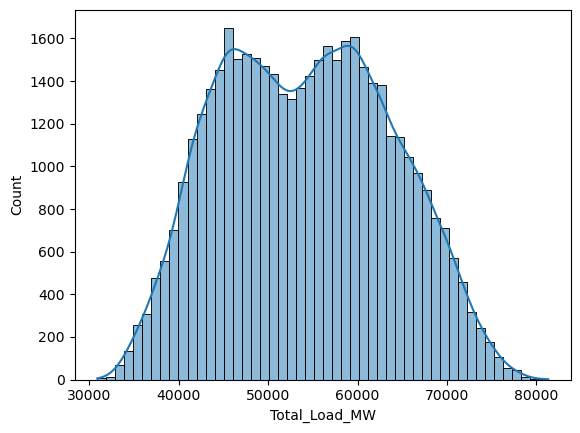

In [19]:
sns.histplot(hourly["Total_Load_MW"], bins=50, kde=True)